# Advanced Exploratory Data Analysis (EDA) on Dataset 3 (5M Working Sample)

**Dataset Used:** `ecommerce_orders_dataset_50L.csv` (5,000,000 Rows)  

---

## What is this notebook about?

In our earlier dataset comparison, we chose **Dataset 3** because it has realistic e-commerce distributions, 0% missing values, and no synthetic artifacts.

Before training any machine learning models, we need to understand the mathematical properties of this dataset:
1. **Are the relationships linear or non-linear?** (Does return risk increase in a straight line with price, or does it curve or flatten out?)
2. **Does the data fit simple linear models like Logistic Regression?** (We will check if log-odds follow a straight line or if key assumptions are broken.)
3. **Are there sudden policy jumps?** (For example, does free shipping at $50 change how often customers return items?)
4. **Which categorical features actually matter?** (Checking if product category or payment method has real predictive power.)
5. **Is there multicollinearity?** (Checking if `order_total`, `unit_price`, and `quantity` repeat each other.)
6. **Which classical ML models should we choose and why?** 


## 1. Loading the Data and Initial Check

We load our working sample of 5,000,000 rows (`ecommerce_orders_dataset_50L.csv`) and check its shape, columns, and data types.


In [1]:
import os
import time
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Set up clean plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'

# Path to our 50L working dataset
candidate_paths = [
    r"../../dataset/Dataset 3/ecommerce_orders_dataset_50L.csv",
    r"../dataset/Dataset 3/ecommerce_orders_dataset_50L.csv",
    r"dataset/Dataset 3/ecommerce_orders_dataset_50L.csv",
    r"D:\College\DS605\ECOMMERCE COPY\dataset\Dataset 3\ecommerce_orders_dataset_50L.csv"
]
dataset_path = next((p for p in candidate_paths if os.path.exists(p)), candidate_paths[-1])

print(f"Loading dataset from: {dataset_path}")
t0 = time.time()
df = pd.read_csv(dataset_path)
print(f"Loaded successfully in {time.time() - t0:.2f} seconds.")
print(f"Rows: {df.shape[0]:,}, Columns: {df.shape[1]}")
print(f"Missing values across columns:\n{df.isnull().sum()}")
df.head()


Loading dataset from: D:\College\DS605\ECOMMERCE COPY\dataset\Dataset 3\ecommerce_orders_dataset_50L.csv
Loaded successfully in 17.70 seconds.
Rows: 5,000,000, Columns: 12
Missing values across columns:
order_id            0
customer_id         0
order_date          0
product_category    0
product_id          0
quantity            0
unit_price          0
order_total         0
payment_method      0
shipping_cost       0
order_status        0
discount_applied    0
dtype: int64


order_id,customer_id,order_date,product_category,product_id,quantity,unit_price,order_total,payment_method,shipping_cost,order_status,discount_applied
ORD0000000000,CUST06438651,2024-12-03,grocery,SKU-GRO-34044,5,4.83,31.59,credit_card,7.44,delivered,False
ORD0000000001,CUST04024143,2025-03-19,home,SKU-HOM-22793,1,101.25,101.25,credit_card,0.00,delivered,False
ORD0000000002,CUST08227616,2025-06-16,grocery,SKU-GRO-47426,1,13.88,18.06,credit_card,4.18,processing,False
ORD0000000003,CUST05454291,2025-07-27,electronics,SKU-ELE-39207,4,416.63,1666.52,credit_card,0.00,delivered,False
ORD0000000004,CUST04434141,2024-03-11,home,SKU-HOM-09643,3,104.94,314.82,paypal,0.00,delivered,False


## 2. Defining the Target: Delivered vs. Returned Orders

In the dataset, orders have 5 different statuses: `delivered`, `shipped`, `returned`, `processing`, and `cancelled`.

- An order that is still **`processing`** or **`shipped`** is currently in transit. We cannot know yet if the customer will keep it or return it. Including them would add noise or unverified labels.
- A **`cancelled`** order was cancelled before it was ever delivered to the customer, so it is not a product return.
- Therefore, to teach our models how to predict whether a customer will return a delivered product, we only keep completed orders where the final outcome is known:
  - **`0 = Delivered (Kept by customer)`**
  - **`1 = Returned (Returned by customer)`**


=== All Order Statuses in the 5M Dataset ===

Final in-scope orders: 3,999,025 (79.98% of total)
Kept items (0): 3,547,206 (88.70%)
Returned items (1): 451,819 (11.30%)
Class imbalance: 7.85 to 1 (~11.3% return rate)


,Order Count,Percentage (%)
order_status,,
delivered,3547206,70.94
shipped,499914,10.00
returned,451819,9.04
processing,300401,6.01
cancelled,200660,4.01


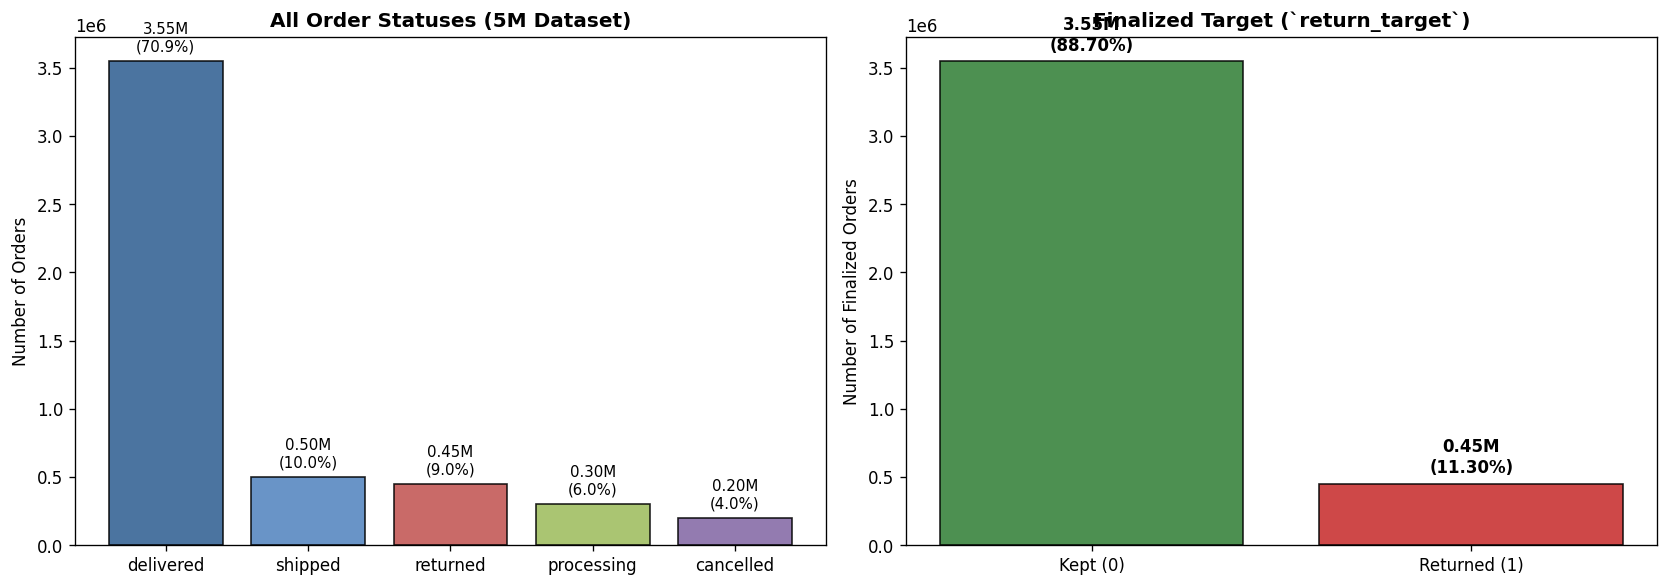

In [2]:
# Check order status breakdown
status_counts = df['order_status'].value_counts()
status_pcts = df['order_status'].value_counts(normalize=True) * 100

status_summary = pd.DataFrame({
    'Order Count': status_counts,
    'Percentage (%)': status_pcts.round(2)
})
print("=== All Order Statuses in the 5M Dataset ===")
display(status_summary)

# Filter for finalized orders (delivered vs returned)
df_final = df[df['order_status'].isin(['delivered', 'returned'])].copy()
df_final['return_target'] = (df_final['order_status'] == 'returned').astype(int)

target_counts = df_final['return_target'].value_counts()
target_pcts = df_final['return_target'].value_counts(normalize=True) * 100

print(f"\nFinal in-scope orders: {len(df_final):,} ({len(df_final)/len(df)*100:.2f}% of total)")
print(f"Kept items (0): {target_counts[0]:,} ({target_pcts[0]:.2f}%)")
print(f"Returned items (1): {target_counts[1]:,} ({target_pcts[1]:.2f}%)")
print(f"Class imbalance: {target_counts[0] / target_counts[1]:.2f} to 1 (~11.3% return rate)")

# Plotting the order funnel and target distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# All statuses
colors1 = ['#2b5c8f', '#4f81bd', '#c0504d', '#9bbb59', '#8064a2']
bars1 = ax1.bar(status_counts.index, status_counts.values, color=colors1, edgecolor='black', alpha=0.85)
ax1.set_title('All Order Statuses (5M Dataset)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Number of Orders')
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, h + 50000, f'{h/1e6:.2f}M\n({h/len(df)*100:.1f}%)', 
             ha='center', va='bottom', fontsize=9)

# Finalized target
colors2 = ['#2e7d32', '#c62828']
bars2 = ax2.bar(['Kept (0)', 'Returned (1)'], target_counts.values, color=colors2, edgecolor='black', alpha=0.85)
ax2.set_title('Finalized Target (`return_target`)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Number of Finalized Orders')
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, h + 50000, f'{h/1e6:.2f}M\n({h/len(df_final)*100:.2f}%)', 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


## 3. Test 1: Linear vs. Non-Linear Relationships (Pearson vs. Spearman)

Before choosing between linear models and tree-based models, we need to test whether the relationships are straight lines or curved.

### Interpretation of this Test:
- **Pearson correlation ($r$):** Measures strictly **straight-line** relationships. If $r$ is low, it either means there is no relationship, or the relationship is curved.
- **Spearman correlation ($
ho$):** Measures **rank-order** relationships. It checks whether one value tends to go up when the other goes up, even if the graph is curved or step-like.


In [3]:
# Comparing Pearson (linear) and Spearman (rank) correlation
num_cols = ['quantity', 'unit_price', 'order_total', 'shipping_cost']
corr_data = []

for c in num_cols:
    p_corr, p_val = stats.pearsonr(df_final[c], df_final['return_target'])
    s_corr, s_val = stats.spearmanr(df_final[c], df_final['return_target'])
    ratio = abs(s_corr) / (abs(p_corr) + 1e-9)
    corr_data.append({
        'Feature': c,
        'Pearson r (Linear)': round(p_corr, 5),
        'Spearman rho (Rank)': round(s_corr, 5),
        'Ratio (|rho| / |r|)': round(ratio, 2),
        'What it tells us': 'Strong Non-Linear Curve' if ratio > 1.8 else 'Mostly Linear'
    })

corr_df = pd.DataFrame(corr_data)
display(corr_df)


Feature,Pearson r (Linear),Spearman rho (Rank),Ratio (|rho| / |r|),What it tells us
quantity,-0.00068,-0.00085,1.26,Mostly Linear
unit_price,0.04173,0.08945,2.14,Strong Non-Linear Curve
order_total,0.03167,0.07871,2.49,Strong Non-Linear Curve
shipping_cost,-0.07999,-0.08113,1.01,Mostly Linear


### Interpreting the results
1. For **`unit_price`**, Spearman correlation (+0.089) is **more than double** Pearson (+0.042).
2. For **`order_total`**, Spearman correlation (+0.079) is **2.5 times higher** than Pearson (+0.032).
3. This is direct statistical evidence that return risk does not increase in a straight line. The pattern is curved, which means classical linear models will need extra feature engineering, while tree models will naturally handle it.

---

## 4. Test 2: Checking the Straight-Line Assumption for Logistic Regression (Log-Odds Check)

Logistic Regression has an important mathematical rule: it assumes that as a feature (like price) increases, the **log-odds** of returning the product changes in a **straight line**.
$$\text{log-odds} = \ln\left(\frac{p}{1 - p}\right) = \beta_0 + \beta_1 \times \text{feature}$$

### Interpretation of this Test:
- We divide `unit_price` and `order_total` into 15 equal bins from smallest to largest.
- For each bin, we calculate the actual return rate ($p$) and its log-odds.
- If the dots form a straight line, Logistic Regression fits well. If the dots bend, curve, or flatten, the straight-line assumption is broken.

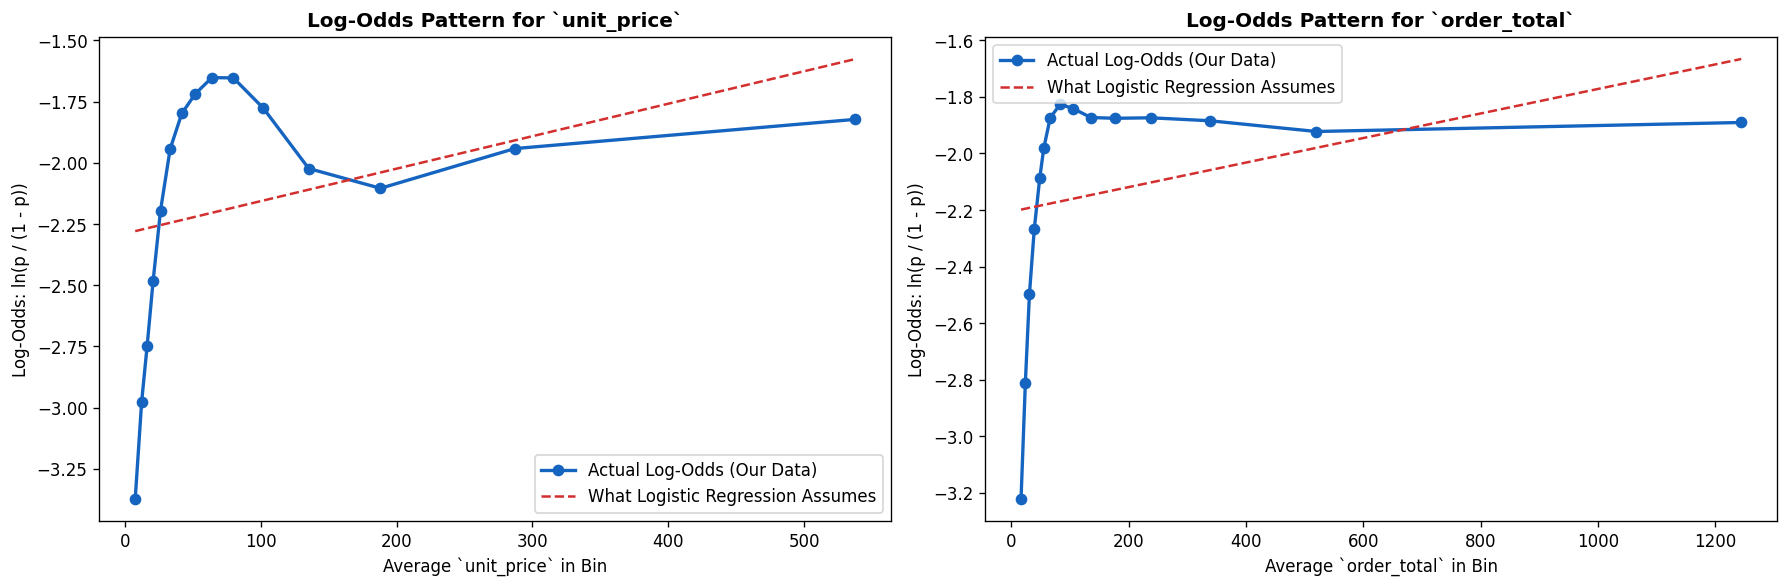

=== Return Rates Across Unit Price Bins ===


unit_price_bin,Avg_Price,Return_Rate,Total_Orders
"(2.009, 10.33]",7.6352,0.0332,266902
"(10.33, 14.36]",12.3785,0.0485,266865
"(14.36, 18.46]",16.3790,0.0601,266478
"(18.46, 23.28]",20.7861,0.0770,266169
"(23.28, 29.51]",26.2546,0.1002,266653
"(29.51, 37.45]",33.3701,0.1254,266751
"(37.45, 46.64]",41.9506,0.1421,266584
"(46.64, 57.49]",51.8911,0.1521,266499
"(57.49, 71.23]",64.0593,0.1608,266559
"(71.23, 89.53]",79.8854,0.1607,266666


In [4]:
# Check if log-odds changes linearly with unit_price and order_total
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for idx, col in enumerate(['unit_price', 'order_total']):
    # Divide into 15 equal-sized bins
    df_final[f'{col}_bin'] = pd.qcut(df_final[col], q=15, duplicates='drop')
    grouped = df_final.groupby(f'{col}_bin', observed=False).agg(
        mean_val=(col, 'mean'),
        return_rate=('return_target', 'mean'),
        count=('return_target', 'count')
    ).reset_index()
    
    # Calculate log-odds: ln(p / (1 - p))
    grouped['log_odds'] = np.log(grouped['return_rate'] / (1.0 - grouped['return_rate']))
    
    ax = axes[idx]
    # Plot empirical log-odds
    ax.plot(grouped['mean_val'], grouped['log_odds'], marker='o', color='#1565c0', linewidth=2, label='Actual Log-Odds (Our Data)')
    
    # Fit hypothetical straight line
    reg = LinearRegression().fit(grouped[['mean_val']], grouped['log_odds'])
    x_line = np.linspace(grouped['mean_val'].min(), grouped['mean_val'].max(), 100)
    y_line = reg.predict(x_line.reshape(-1, 1))
    ax.plot(x_line, y_line, '--', color='#d32f2f', linewidth=1.5, label='What Logistic Regression Assumes')
    
    ax.set_title(f'Log-Odds Pattern for `{col}`', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'Average `{col}` in Bin')
    ax.set_ylabel('Log-Odds: ln(p / (1 - p))')
    ax.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

# Show table for unit_price bins
print("=== Return Rates Across Unit Price Bins ===")
price_table = df_final.groupby('unit_price_bin', observed=False).agg(
    Avg_Price=('unit_price', 'mean'),
    Return_Rate=('return_target', 'mean'),
    Total_Orders=('return_target', 'count')
).round(4).reset_index()
display(price_table)


### Interpreting the results
1. **`unit_price` curves like an upside-down 'U':**
   - For very cheap items (<$10), return rate is very low (**3.3%**).
   - As price increases to $50–$80 (standard clothing and shoes range), return rate peaks at **16.1%**.
   - For expensive items ($100–$250), return rate drops back down to **10.8%** before leveling out.
   - *Why this happens:* People return mid-priced clothes often because of sizing issues. But when they buy expensive electronics or appliances, they research carefully before buying, so returns drop.
2. **`order_total` flattens completely (Saturation Plateau):**
   - From $16 to $55, return rate rises quickly from 3.8% to 12.5%.
   - But after $60, whether the order is $150 or $3,000, **the return rate stays almost flat around 13%**.
   - *What this means:* A simple straight-line model would wrongly assume that a $3,000 order has an enormous return rate. In reality, it flattens out. Tree models (like Random Forest and LightGBM) handle this plateau naturally.

---

## 5. Test 3: Which Categorical Features Actually Matter? (Chi-Square & Cramér's V)

We want to know which category features actually have predictive power and which ones are just noise.

### Interpretation of this Test:
- **Chi-Square ($\chi^2$):** Tests whether different groups (like clothing vs. books) have statistically different return rates.
- **Cramér's V:** Measures **how strong** that difference is on a scale from 0 to 1:
  - Close to 0 = No real effect / useless.
  - Above 0.15 = Very strong feature with real impact.


Feature,Chi-Square,p-value,Cramer's V (0 to 1),Importance
product_category,176916.95,0.00e+00,0.21033,Dominant Feature
payment_method,5.37,2.52e-01,0.00116,No Impact / Noise
discount_applied,77.13,1.60e-18,0.00439,Weak


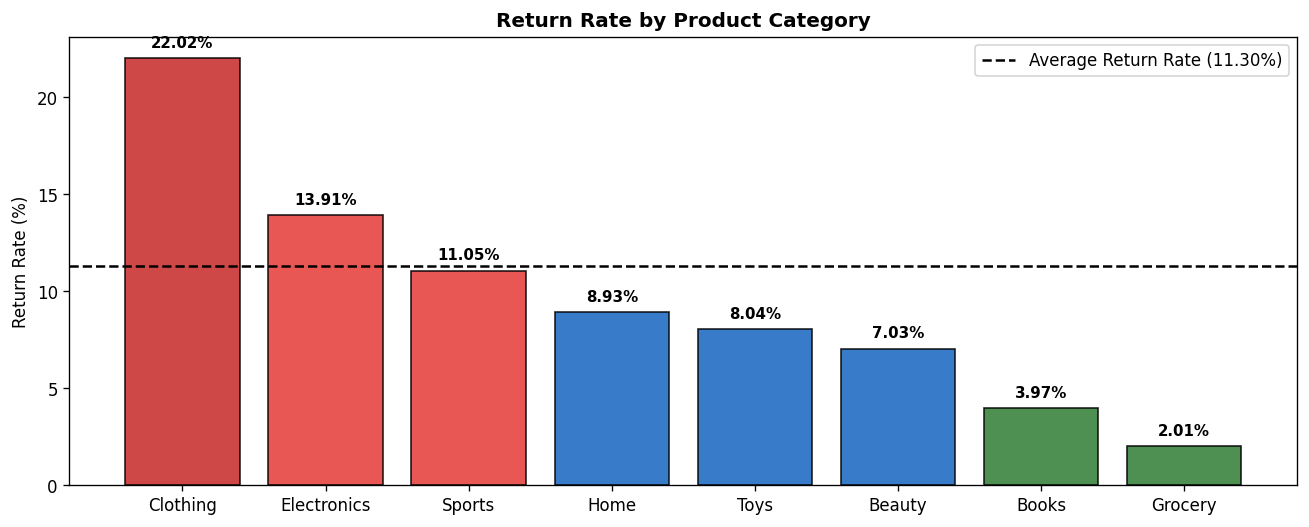

In [5]:
# Chi-Square and Cramer's V test for categorical features
cat_cols = ['product_category', 'payment_method', 'discount_applied']
chi2_results = []

for cat in cat_cols:
    contingency = pd.crosstab(df_final[cat], df_final['return_target'])
    chi2, p, dof, _ = stats.chi2_contingency(contingency)
    n = contingency.sum().sum()
    r, k = contingency.shape
    cramers_v = np.sqrt(chi2 / (n * (min(k, r) - 1)))
    chi2_results.append({
        'Feature': cat,
        'Chi-Square': round(chi2, 2),
        'p-value': f"{p:.2e}",
        "Cramer's V (0 to 1)": round(cramers_v, 5),
        'Importance': 'Dominant Feature' if cramers_v > 0.15 else 'Weak' if p < 0.05 else 'No Impact / Noise'
    })

display(pd.DataFrame(chi2_results))

# Look at actual return rate by product category
cat_rates = df_final.groupby('product_category').agg(
    Total_Orders=('return_target', 'count'),
    Returned_Orders=('return_target', 'sum'),
    Return_Rate=('return_target', 'mean')
).sort_values(by='Return_Rate', ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(11, 4.5))
colors = ['#c62828' if r > 0.15 else '#e53935' if r > 0.10 else '#2e7d32' if r < 0.05 else '#1565c0' for r in cat_rates['Return_Rate']]
bars = ax.bar(cat_rates['product_category'].str.capitalize(), cat_rates['Return_Rate'] * 100, color=colors, edgecolor='black', alpha=0.85)

ax.axhline(df_final['return_target'].mean() * 100, color='black', linestyle='--', label=f'Average Return Rate ({df_final["return_target"].mean()*100:.2f}%)')
ax.set_title('Return Rate by Product Category', fontsize=12, fontweight='bold')
ax.set_ylabel('Return Rate (%)')
ax.legend(frameon=True, facecolor='white')

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, h + 0.4, f'{h:.2f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### Interpreting the results
1. **`product_category` is our most powerful feature:**
   - Chi-Square is massive (176,916), and Cramér's V is **0.21** (very strong).
   - **Clothing has a 22.02% return rate** (more than 1 in 5 orders are returned).
   - **Groceries have only a 2.01% return rate** (returns are practically zero).
   - Books return at 3.97%, while Electronics return at 13.91%. This huge real-world difference will be the primary signal for our classifiers.
2. **`payment_method` has virtually no effect:**
   - Chi-square is only 5.37 ($p = 0.25$).
   - Whether the customer pays with a credit card, debit card, PayPal, or Buy-Now-Pay-Later, the return rate stays almost identical (~11.2% to 11.5%). It is essentially statistical noise.

---

## 6. Test 4: The $50 Free Shipping Rule & Multicollinearity (VIF)

### A. The $50 Free Shipping Jump
In this dataset, there is a clear company policy: orders above $50 get free shipping ($0 fee). Does this sudden policy jump affect return rates?

### B. Multicollinearity (VIF)
We also know that:
$$\text{order\_total} = (\text{quantity} \times \text{unit\_price}) + \text{shipping\_cost}$$
Because total amount is calculated directly from price and quantity, they share information. We run the **Variance Inflation Factor (VIF)** test to check if they are too correlated for linear models.
- VIF < 5: Moderate correlation (manageable with regularization).
- VIF > 10: Severe correlation (one feature should be dropped).


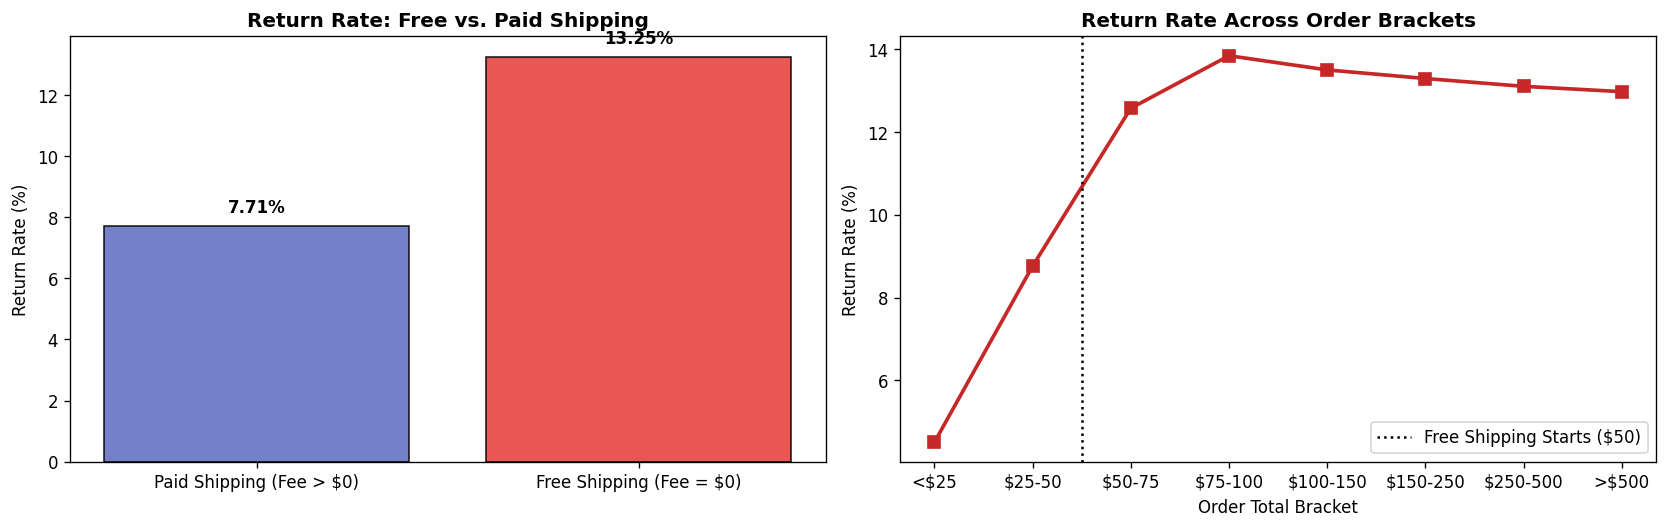

=== Variance Inflation Factor (VIF) Results ===


Feature,R-squared with others,VIF Score,Interpretation
quantity,0.4498,1.82,Low correlation
unit_price,0.7520,4.03,Moderate correlation (Needs regularization)
order_total,0.7540,4.07,Moderate correlation (Needs regularization)
shipping_cost,0.3014,1.43,Low correlation


In [6]:
# 1. Compare Free Shipping vs Paid Shipping
df_final['has_free_shipping'] = (df_final['shipping_cost'] == 0.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ship_summary = df_final.groupby('has_free_shipping')['return_target'].agg(['count', 'mean']).reset_index()
bars = ax1.bar(['Paid Shipping (Fee > $0)', 'Free Shipping (Fee = $0)'], ship_summary['mean'] * 100, 
               color=['#5c6bc0', '#e53935'], edgecolor='black', alpha=0.85)
ax1.set_title('Return Rate: Free vs. Paid Shipping', fontsize=12, fontweight='bold')
ax1.set_ylabel('Return Rate (%)')
for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, h + 0.3, f'{h:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Return rate across order value brackets
bins = [0, 25, 50, 75, 100, 150, 250, 500, 10000]
bin_labels = ['<$25', '$25-50', '$50-75', '$75-100', '$100-150', '$150-250', '$250-500', '>$500']
df_final['order_bracket'] = pd.cut(df_final['order_total'], bins=bins, labels=bin_labels)
bracket_rates = df_final.groupby('order_bracket', observed=False)['return_target'].mean() * 100

ax2.plot(bin_labels, bracket_rates.values, marker='s', color='#c62828', linewidth=2.2, markersize=7)
ax2.axvline(x=1.5, color='black', linestyle=':', label='Free Shipping Starts ($50)')
ax2.set_title('Return Rate Across Order Brackets', fontsize=12, fontweight='bold')
ax2.set_ylabel('Return Rate (%)')
ax2.set_xlabel('Order Total Bracket')
ax2.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

# 3. Check VIF for continuous features
num_features = ['quantity', 'unit_price', 'order_total', 'shipping_cost']
vif_records = []

for feat in num_features:
    X_others = df_final[[c for c in num_features if c != feat]]
    y_feat = df_final[feat]
    reg = LinearRegression().fit(X_others, y_feat)
    r2 = reg.score(X_others, y_feat)
    vif = 1.0 / (1.0 - r2) if r2 < 1.0 else np.inf
    vif_records.append({
        'Feature': feat,
        'R-squared with others': round(r2, 4),
        'VIF Score': round(vif, 2),
        'Interpretation': 'Moderate correlation (Needs regularization)' if vif > 3.0 else 'Low correlation'
    })

print("=== Variance Inflation Factor (VIF) Results ===")
display(pd.DataFrame(vif_records))


### Interpreting the results
1. **Free Shipping almost doubles returns:**
   - Paid shipping orders return at **7.71%**.
   - Free shipping orders return at **13.25%** (almost double).
   - This creates a sudden threshold jump at $50. Decision tree models are great at this because a tree can simply make a split like `shipping_cost == 0`.
2. **VIF scores are around 4.0 for price and total:**
   - A score of 4.0 means there is moderate correlation between `order_total` and `unit_price`.
   - It is below the danger threshold of 10, so we don't need to throw features away. But if we use Logistic Regression, we must use regularization (L2/Ridge penalty) to keep weights stable. Tree models are naturally immune to this.

---

## 7. Final Model Selection: Which Models We Are Choosing and Why

Based on all the empirical tests we performed in this Advanced EDA:
- Strong non-linear curves in unit price and order total
- Sudden jump at $50 free shipping
- Huge differences across product categories (22% in clothing vs. 2% in groceries)
- 7.85:1 class imbalance
- Moderate correlation between price and total (VIF ~ 4)

We have finalized **4 candidate classical ML models and 1 ensemble model**

### 1. Model 1: Regularized Logistic Regression (ElasticNet / L2)
- **What it is:** Our classical linear baseline model.
- **Why we are choosing it:**
  - It is fast, simple, and easy to explain.
  - It provides clean probability scores from 0 to 1.
  - It serves as our mandatory baseline: by testing Logistic Regression first, we can see exactly how much improvement non-linear tree models provide.
  - We will use L2/ElasticNet regularization to handle the correlated price features (VIF ~ 4) and use balanced class weights to handle the 7.85:1 class imbalance.

### 2. Model 2: Random Forest Classifier
- **What it is:** A classical bagging model that trains many independent decision trees on random samples of the data and averages their votes.
- **Why we are choosing it:**
  - Since trees split data based on rank rather than numerical distance, Random Forest does not care about extreme price outliers ($1,000+ orders) and requires no special scaling.
  - It easily captures combinations of features (like expensive clothes having much higher returns than cheap clothes).
  - Averaging 100+ trees helps reduce prediction variance and prevents overfitting.

### 3. Model 3: LightGBM Classifier (Our Primary Gradient Boosting Model)
- **What it is:** A fast, high-performance gradient boosting library designed specifically for large tabular datasets.
- **Why we are choosing it:**
  - **Speed on large data:** Training on millions of rows is very fast in LightGBM because it groups continuous values into 256 simple bins (histogram binning).
  - **Handles threshold jumps:** It can effortlessly capture the sharp jump at $50 free shipping and the flat plateau in order total.
  - **Native class imbalance support:** It has a built-in `scale_pos_weight = 7.85` parameter that automatically gives more importance to the returned orders during training.

### 4. Model 4: XGBoost Classifier (Challenger Gradient Boosting Model)
- **What it is:** Another industry-standard gradient boosting library that builds trees level-by-level using second-order gradients.
- **Why we are choosing it:**
  - XGBoost builds its trees in a depth-wise structure (compared to LightGBM's leaf-wise structure) and includes built-in penalties on tree leaves.
  - We want to test it side-by-side against LightGBM to see which boosting method gives better precision and recall for returns.

### 5. Model 5: Ensemble Model (Voting / Stacking Classifier)
- **What it is:** A meta-model that combines the predictions of our individual models.
- **Why we are choosing it:**
  - Different models make mistakes in different places: Logistic Regression captures broad overall trends, while tree models capture specific price-category combinations.
  - By combining their probability outputs (either using soft voting or stacking with a meta-learner), we reduce errors, smooth out predictions, and achieve a higher overall F1-score and PR-AUC.

---

## 8. Summary of Next Steps for the Modeling Phase

Now that our data properties are fully understood and our 4+1 models are finalized, our modeling phase will proceed with:
1. **Stratified Splitting:** Splitting data into 80% train and 20% test, keeping the exact ~11.3% return rate and category proportions in both splits.
2. **Preprocessing:** Scaling continuous features and one-hot encoding categories for Logistic Regression; passing data directly for tree models.
3. **Hyperparameter Tuning:** Using cross-validation to tune tree depth, learning rate, and regularization for Random Forest, LightGBM, and XGBoost.
4. **Ensembling:** Combining the best model outputs into our final ensemble.
5. **Threshold Tuning:** Finding the optimal decision threshold to catch as many returns as possible without raising too many false alarms.
